# Mini-Project 2 — Uganda tax engine
Author: MAGALA MUHUSINU , REG_NO S26M19/046, ACCESS_NO B40820. FY 2026/27 teaching model. Extension B: TaxPlanner. Actual financial arithmetic is Decimal-only; float appears only in the isolated discussion example.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display, HTML, Markdown

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Launch from repository root or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
rng = np.random.default_rng(2026)


def load_sample(name):
    return json.loads((ROOT / "data" / "samples" / name).read_text(encoding="utf-8"))


def display(obj):
    if isinstance(obj, pd.DataFrame):
        _display(HTML(obj.to_html(index=False)))
    elif isinstance(obj, pd.io.formats.style.Styler):
        _display(HTML(obj.to_html()))
    else:
        _display(obj)

In [2]:
from datetime import date
from decimal import Decimal, ROUND_HALF_UP
from src.tax_engine import *

A = TaxContext(income=Money("1000000"), lst=Money("10000"))
B = TaxContext(income=Money("1200000"), lst=Money("10000"))

## PAYE boundaries: both residency schedules

In [3]:
rows = []
for x in [0, 335000, 335001, 410000, 485000, 10000000, 10000001]:
    rows.append(
        {
            "Chargeable income (UGX)": x,
            "Resident PAYE (UGX)": PAYETax()
            .calculate(TaxContext(income=Money(x)))
            .amount.amount,
            "Nonresident PAYE (UGX)": PAYETax()
            .calculate(TaxContext(income=Money(x), resident=False))
            .amount.amount,
        }
    )
display(pd.DataFrame(rows))
assert rows[-1]["Resident PAYE (UGX)"] == Decimal("2888250.40")

Chargeable income (UGX),Resident PAYE (UGX),Nonresident PAYE (UGX)
0,0.00,0.00
335000,0.00,33500.00
335001,0.20,33500.20
410000,15000.00,48500.00
485000,33750.00,71000.00
10000000,2888250.00,2925500.00
10000001,2888250.40,2925500.40


## Payroll: independent hand calculation and reconciliation

In [4]:
p = Payroll()
first = p.calculate(A)
second = p.calculate(B)
display(pd.DataFrame([{"Item": k, "Amount (UGX)": v.amount} for k, v in first.items()]))
assert first["paye"] == Money("185250") and first["net"] == Money("754750")
assert (
    first["net"] + first["paye"] + first["lst"] + first["nssf_employee"]
    == first["gross"]
)

Item,Amount (UGX)
gross,1000000
lst,10000
paye,185250
nssf_employee,50000
nssf_employer,100000
net,754750


## VAT ledger: categories and eligible input proportions

In [5]:
invoices = (
    Invoice(Money("1000000")),
    Invoice(Money("200000"), "zero"),
    Invoice(Money("300000"), "exempt"),
    Invoice(Money("400000"), direction="purchase"),
    Invoice(Money("100000"), direction="purchase", credit_eligible=False),
    Invoice(Money("200000"), direction="purchase", taxable_use=Decimal("0.5")),
)
display(
    pd.DataFrame(
        [
            {
                "Amount (UGX)": i.amount.amount,
                "Category": i.category,
                "Direction": i.direction,
                "Eligible": i.credit_eligible,
                "Taxable use": i.taxable_use,
            }
            for i in invoices
        ]
    )
)
vat = VATTax().calculate(TaxContext(invoices=invoices))
print(vat)
assert vat.amount == Money("90000")
credit = VATTax().calculate(
    TaxContext(invoices=(Invoice(Money("1000"), direction="purchase"),))
)
print("Credit balance:", credit.amount)
assert credit.amount == Money("-180")

Amount (UGX),Category,Direction,Eligible,Taxable use
1000000,standard,sale,True,1
200000,zero,sale,True,1
300000,exempt,sale,True,1
400000,standard,purchase,True,1
100000,standard,purchase,False,1
200000,standard,purchase,True,0.5


TaxResult(name='Net VAT', amount=UGX 90,000.00, breakdown={'output_vat': UGX 180,000.00, 'input_vat': UGX 90,000.00})
Credit balance: UGX -180.00


## Resident-company tax

In [6]:
corporate = CorporateTax().calculate(
    TaxContext(income=Money("10000000"), deductions=Money("6000000"))
)
print(corporate)
assert corporate.amount == Money("1200000")

TaxResult(name='Corporate income tax', amount=UGX 1,200,000.00, breakdown={'chargeable_income': UGX 4,000,000.00})


## Extension B — compare salary scenarios

Item,A (UGX),B (UGX),B minus A (UGX)
gross,1000000,1200000,200000
lst,10000,10000,0
paye,185250,245250,60000
nssf_employee,50000,60000,10000
nssf_employer,100000,120000,20000
net,754750,884750,130000


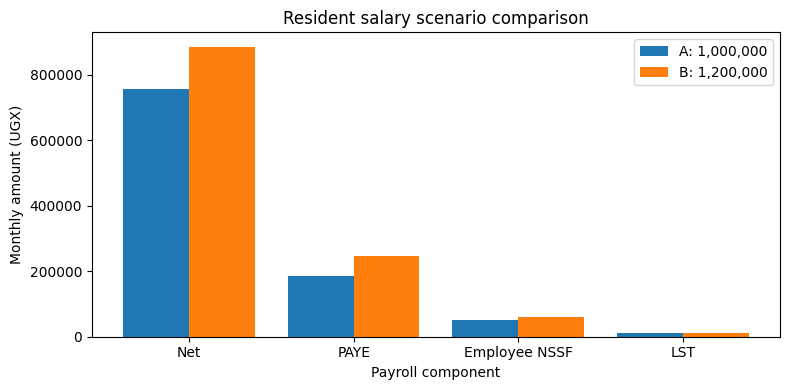

In [7]:
delta = TaxPlanner().compare(A, B)
display(
    pd.DataFrame(
        [
            {
                "Item": k,
                "A (UGX)": first[k].amount,
                "B (UGX)": second[k].amount,
                "B minus A (UGX)": delta[k].amount,
            }
            for k in first
        ]
    )
)
assert delta["net"] == Money("130000")
keys = ["net", "paye", "nssf_employee", "lst"]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, [int(first[k].amount) for k in keys], width=0.4, label="A: 1,000,000")
ax.bar(x + 0.2, [int(second[k].amount) for k in keys], width=0.4, label="B: 1,200,000")
ax.set_xticks(x, ["Net", "PAYE", "Employee NSSF", "LST"])
ax.set(
    xlabel="Payroll component",
    ylabel="Monthly amount (UGX)",
    title="Resident salary scenario comparison",
)
ax.legend()
fig.tight_layout()
plt.show()

## Explicit errors and isolated float demonstration

In [8]:
def expect_error(label, action):
    try:
        action()
    except TaxError as exc:
        print(label, type(exc).__name__, str(exc))
    else:
        raise AssertionError("Expected tax error")


expect_error("Negative", lambda: TaxContext(income=Money(-1)))
expect_error("Date", lambda: PAYETax().calculate(TaxContext(period=date(2026, 6, 30))))
expect_error("NaN", lambda: Money("NaN"))
# Float is deliberately isolated here, never used for tax calculations.
print("Float:", repr(0.1 + 0.2), "equals 0.3:", 0.1 + 0.2 == 0.3)
print("Float 2.675 formatted:", format(2.675, ".2f"))
print("Exact Decimal sum:", Decimal("0.1") + Decimal("0.2"))
print(
    "Decimal rounded:",
    Decimal("2.675").quantize(Decimal("0.01"), rounding=ROUND_HALF_UP),
)
assert Money("0.1") + Money("0.2") == Money("0.3")

Negative InvalidIncomeError income cannot be negative.
Date NoScheduleForDateError Supported: 2026-07-01 to 2027-06-30.
NaN InvalidIncomeError Amount must be finite.
Float: 0.30000000000000004 equals 0.3: False
Float 2.675 formatted: 2.67
Exact Decimal sum: 0.3
Decimal rounded: 2.68


## Mandatory property tests

In [9]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tax_properties.py",
        "-q",
        "--color=no",
    ],
    cwd=ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout.strip().splitlines()[-1])
assert result.returncode == 0, result.stdout + result.stderr

2 passed in 1.13s


## Tax design, discussion and findings

### Schedule and independent calculation
The implemented year is 1 July 2026–30 June 2027. Resident PAYE follows URA's amendment notice [T1]; nonresident PAYE uses its separate published table [T2]. Unsupported dates raise NoScheduleForDateError, not an invented schedule. The nonresident initial band charges 10%, and subsequent bands are not copied from the resident schedule.

At resident income UGX 10,000,000, tax is UGX 2,888,250. At UGX 10,000,001 it is UGX 2,888,250.40 before settlement: ordinary 30% continues and an extra 10% applies only to the excess. Neither tax on the entire salary nor freezing ordinary tax at the threshold is correct.

income is base monthly pay and allowances are additional taxable cash earnings. Gross is their sum. Avoid supplying inclusive gross and then double-counting allowances. Employee NSSF is 5%, employer NSSF 10% of gross [T4]. Employer NSSF is an employer cost, not an employee deduction. Employee NSSF does not reduce the PAYE base; configured LST does [T3]. Annual LST assessment and instalment schedules are outside scope.

Independent check: salary UGX 1,000,000, LST UGX 10,000, no allowances. Chargeable income is 990,000. PAYE = 33,750 + 30% × (990,000 − 485,000) = 185,250. Employee NSSF is 50,000, employer NSSF 100,000. Net = 1,000,000 − 10,000 − 185,250 − 50,000 = UGX 754,750. The configured LST is a scenario assumption, not a universal monthly liability.

### Why float is unsafe
Binary floats cannot exactly represent many decimal fractions: 0.1 + 0.2 != 0.3. Formatting float 2.675 to two decimals can produce 2.67. Decimal('0.1') + Decimal('0.2') is exactly 0.3, and ROUND_HALF_UP maps Decimal('2.675') to 2.68. The notebook's float example is deliberately isolated from tax arithmetic.

Money rejects floats, bools, NaN and infinity. It implements addition, multiplication, comparison, repr and subtraction. Calculations retain exact fractional shillings; Payroll rounds final PAYE and each NSSF contribution once to whole UGX using ROUND_HALF_UP. LST must already be whole UGX. This is a project settlement policy, not a sourced assertion about all statutory forms. Exact boundary tests retain UGX 0.20 PAYE at income 335,001 instead of rounding away the marginal result.

### Inheritance and composition
Tax is abstract and defines calculate(ctx: TaxContext) -> TaxResult. PAYETax, NSSFTax, VATTax and CorporateTax inherit because they implement interchangeable tax policies. TaxError has InvalidIncomeError and NoScheduleForDateError specializations so callers can distinguish financial validation from unavailable schedules. Invalid inputs never silently become zero-tax results.

Payroll composes PAYE and NSSF rather than inheriting Tax: coordinating multiple liabilities is not a single tax policy. Money and Invoice are value objects, not tax subclasses. Residency differences remain within one cohesive PAYE policy rather than duplicated payroll hierarchies. TaxPlanner composes the same Payroll and compares immutable input contexts.

### VAT, corporate tax and extension B
Invoices are tax-exclusive. Standard VAT is 18%; zero-rated and exempt sales both generate zero output VAT but remain distinct categories [T5]. Input credit requires credit_eligible plus a taxable_use fraction. Purchases wholly attributable to exempt supplies must have no eligible taxable use. The caller determines legal eligibility and statutory apportionment; the model does not infer entitlement merely because an invoice is a purchase.

Example output VAT is 180,000. Eligible purchases of 400,000 yield 72,000 input VAT; a 200,000 purchase with 50% eligible use adds 18,000. The ineligible purchase contributes no credit. Net VAT is UGX 90,000. Negative net VAT is retained as a credit balance, not an automatically approved refund.

Resident corporate tax is the standard 30% of nonnegative revenue less allowable deductions [T6]. Revenue 10,000,000 less deductions 6,000,000 gives tax UGX 1,200,000. Loss carry-forwards, sectoral exemptions and capital-allowance rules are outside scope.

Extension B compares salary 1,000,000 with 1,200,000, holding LST at 10,000. Added salary 200,000 is reduced by 60,000 additional PAYE and 10,000 employee NSSF, leaving 130,000 extra net pay. Employer NSSF rises separately by 20,000. This is a salary-versus-salary comparison, not unsupported dividend modelling.

### Validation and limits
Tests cover both residency schedules at all required edges, money errors, allowances, payroll reconciliation, VAT eligibility/credits, corporate losses and planner differences. A dense deterministic sweep checks nonnegative, monotonic PAYE bounded by income. Mandatory Hypothesis tests generate decimal incomes and residency flags with repeatable settings. These tests are executed from the property-test cell above, which reported that both passed, and they also run with `python -m pytest`. The sweep is additional coverage, not a replacement. This teaching software is not production tax advice.


# Sources and versions
Checked 16 October 2026: the non-resident bands against URA's published PAYE rates table, and the resident 2026/27 bands against the assignment brief and the Income Tax (Amendment) Act 2026 changes [T1]. Reverify before relying on this teaching implementation. Links are not bundled copies of legal instruments.

- T0 Assignment 2 brief (baseline resident bands, 10% surcharge above UGX 10,000,000)
- T1 URA 2026 PAYE amendment notice (7 September 2026, effective 1 July 2026): https://ura.go.ug/en/changes-to-paye-return-form-following-the-income-tax-amendment-act-2026/
- T2 Separate resident/nonresident tables: https://ura.go.ug/en/domestic-taxes/paye-rates/
- T3 Employment income FY 2026/27: https://ura.go.ug/storage/2026/09/EMPLOYMENT-INCOME-ENGLISH-2026-27-1.pdf ; https://ura.go.ug/en/employment-income/
- T4 NSSF: https://www.nssfug.org/about-us/membership/
- T5 VAT: https://ura.go.ug/en/manufacturing-sector-2/
- T6 Corporate: https://ura.go.ug/en/corporation-tax/

ROUND_HALF_UP whole-UGX settlement is a project policy, not a claim about all statutory forms. Standard rates do not imply all sectoral exceptions are implemented.
